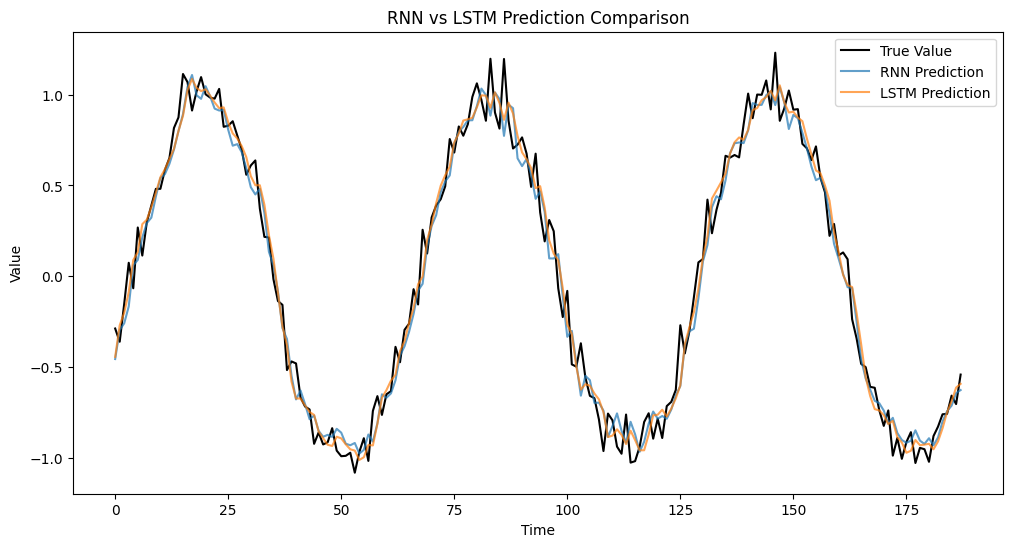

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ===== 1️⃣ 產生假時間序列資料 =====
np.random.seed(0)
torch.manual_seed(0)

t = np.linspace(0, 100, 1000)
data = np.sin(t) + 0.1*np.random.randn(len(t))  # 加一點雜訊

seq_length = 60 #20

X = []
Y = []

for i in range(len(data) - seq_length):
    X.append(data[i:i+seq_length])
    Y.append(data[i+seq_length])

X = np.array(X)
Y = np.array(Y)

# 切分訓練與測試
train_size = int(len(X) * 0.8)

X_train = torch.tensor(X[:train_size], dtype=torch.float32).unsqueeze(-1)
Y_train = torch.tensor(Y[:train_size], dtype=torch.float32).unsqueeze(-1)

X_test = torch.tensor(X[train_size:], dtype=torch.float32).unsqueeze(-1)
Y_test = torch.tensor(Y[train_size:], dtype=torch.float32).unsqueeze(-1)

# ===== 2️⃣ 定義模型 =====

class RNNModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=50):
        super(RNNModel, self).__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        out = out[:, -1, :]
        out = self.fc(out)
        return out


class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=50):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.fc(out)
        return out


# ===== 3️⃣ 訓練函數 =====

def train_model(model, X_train, Y_train, epochs=50):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(epochs):
        model.train()
        output = model(X_train)
        loss = criterion(output, Y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    return model


# ===== 4️⃣ 訓練兩個模型 =====

rnn_model = RNNModel()
lstm_model = LSTMModel()

rnn_model = train_model(rnn_model, X_train, Y_train)
lstm_model = train_model(lstm_model, X_train, Y_train)

# ===== 5️⃣ 預測 =====

rnn_model.eval()
lstm_model.eval()

with torch.no_grad():
    rnn_pred = rnn_model(X_test).numpy()
    lstm_pred = lstm_model(X_test).numpy()

# ===== 6️⃣ 畫圖比較 =====

plt.figure(figsize=(12,6))

plt.plot(Y_test.numpy(), label="True Value", color="black")
plt.plot(rnn_pred, label="RNN Prediction", alpha=0.7)
plt.plot(lstm_pred, label="LSTM Prediction", alpha=0.7)

plt.legend()
plt.title("RNN vs LSTM Prediction Comparison")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

RNN  MSE: 0.015633955597877502
LSTM MSE: 0.013154405169188976
GRU  MSE: 0.01343325711786747


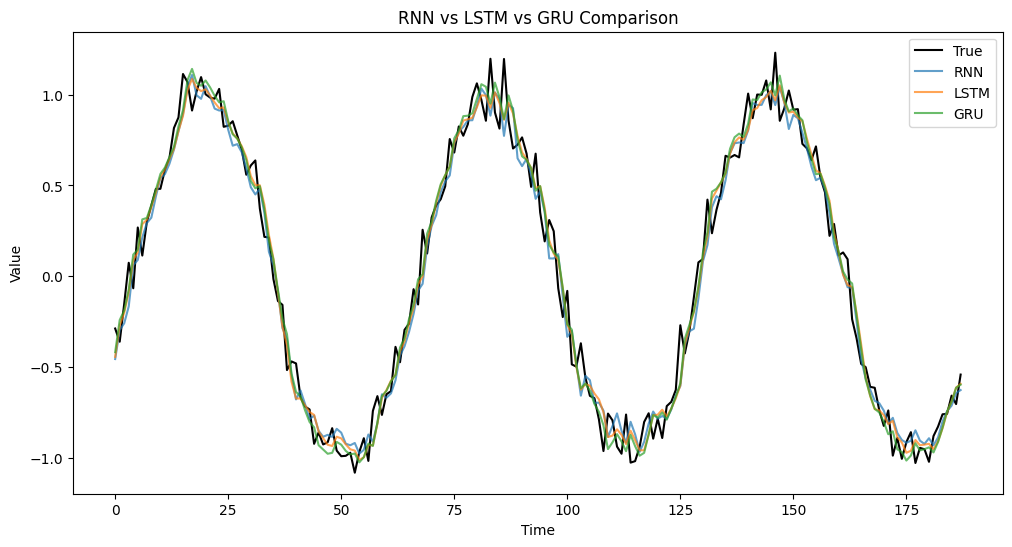

In [3]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ===== 1️⃣ 產生時間序列資料 =====
np.random.seed(0)
torch.manual_seed(0)

t = np.linspace(0, 100, 1000)
data = np.sin(t) + 0.1*np.random.randn(len(t))

seq_length = 60   # 序列越長差距越明顯

X, Y = [], []

for i in range(len(data) - seq_length):
    X.append(data[i:i+seq_length])
    Y.append(data[i+seq_length])

X = np.array(X)
Y = np.array(Y)

train_size = int(len(X) * 0.8)

X_train = torch.tensor(X[:train_size], dtype=torch.float32).unsqueeze(-1)
Y_train = torch.tensor(Y[:train_size], dtype=torch.float32).unsqueeze(-1)

X_test = torch.tensor(X[train_size:], dtype=torch.float32).unsqueeze(-1)
Y_test = torch.tensor(Y[train_size:], dtype=torch.float32).unsqueeze(-1)

# ===== 2️⃣ 定義三種模型 =====

class RNNModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=50):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.fc(out[:, -1, :])
        return out


class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=50):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out


class GRUModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=50):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out


# ===== 3️⃣ 訓練函數 =====

def train_model(model, X_train, Y_train, epochs=50):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(epochs):
        model.train()
        output = model(X_train)
        loss = criterion(output, Y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    return model


# ===== 4️⃣ 建立並訓練模型 =====

rnn_model = train_model(RNNModel(), X_train, Y_train)
lstm_model = train_model(LSTMModel(), X_train, Y_train)
gru_model = train_model(GRUModel(), X_train, Y_train)

# ===== 5️⃣ 預測 =====

def evaluate(model, X_test, Y_test):
    model.eval()
    with torch.no_grad():
        pred = model(X_test)
        mse = nn.MSELoss()(pred, Y_test).item()
    return pred.numpy(), mse

rnn_pred, rnn_mse = evaluate(rnn_model, X_test, Y_test)
lstm_pred, lstm_mse = evaluate(lstm_model, X_test, Y_test)
gru_pred, gru_mse = evaluate(gru_model, X_test, Y_test)

# ===== 6️⃣ 印出誤差 =====

print("RNN  MSE:", rnn_mse)
print("LSTM MSE:", lstm_mse)
print("GRU  MSE:", gru_mse)

# ===== 7️⃣ 畫圖比較 =====

plt.figure(figsize=(12,6))

plt.plot(Y_test.numpy(), label="True", color="black")
plt.plot(rnn_pred, label="RNN", alpha=0.7)
plt.plot(lstm_pred, label="LSTM", alpha=0.7)
plt.plot(gru_pred, label="GRU", alpha=0.7)

plt.legend()
plt.title("RNN vs LSTM vs GRU Comparison")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

RNN        MSE: 0.015633955597877502
LSTM       MSE: 0.013154405169188976
GRU        MSE: 0.01343325711786747
Transformer MSE: 0.022722959518432617


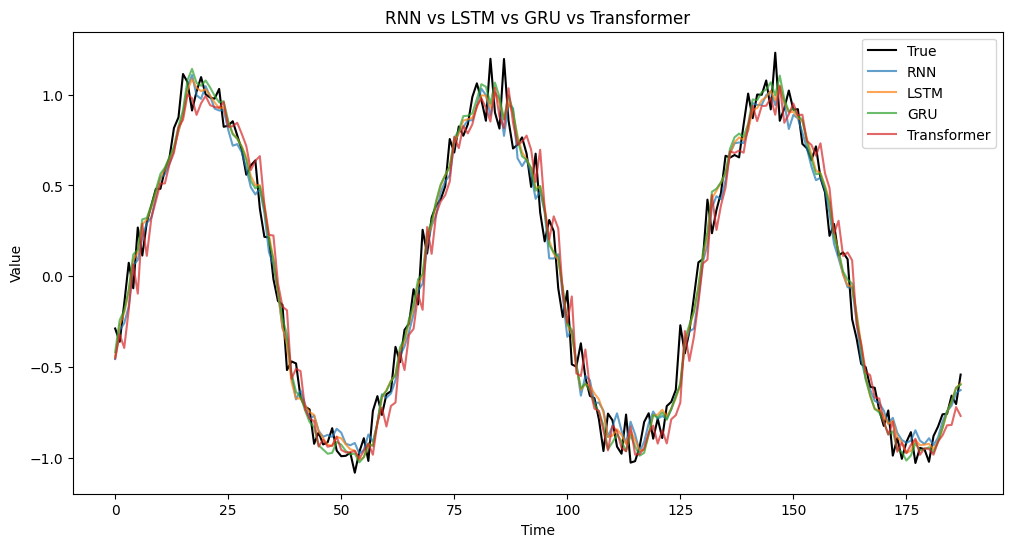

In [4]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# =========================
# 1️⃣ 產生時間序列資料
# =========================
np.random.seed(0)
torch.manual_seed(0)

t = np.linspace(0, 100, 1000)
data = np.sin(t) + 0.1*np.random.randn(len(t))

seq_length = 60

X, Y = [], []
for i in range(len(data) - seq_length):
    X.append(data[i:i+seq_length])
    Y.append(data[i+seq_length])

X = np.array(X)
Y = np.array(Y)

train_size = int(len(X) * 0.8)

X_train = torch.tensor(X[:train_size], dtype=torch.float32).unsqueeze(-1)
Y_train = torch.tensor(Y[:train_size], dtype=torch.float32).unsqueeze(-1)

X_test = torch.tensor(X[train_size:], dtype=torch.float32).unsqueeze(-1)
Y_test = torch.tensor(Y[train_size:], dtype=torch.float32).unsqueeze(-1)


# =========================
# 2️⃣ 定義模型
# =========================

class RNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(1, 50, batch_first=True)
        self.fc = nn.Linear(50, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 50, batch_first=True)
        self.fc = nn.Linear(50, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


class GRUModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(1, 50, batch_first=True)
        self.fc = nn.Linear(50, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :])


# ✅ Transformer 模型
class TransformerModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Linear(1, 32)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=32,
            nhead=4,
            dim_feedforward=64,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        x = self.embedding(x)
        x = self.transformer(x)
        return self.fc(x[:, -1, :])


# =========================
# 3️⃣ 訓練函數
# =========================

def train_model(model, X_train, Y_train, epochs=50):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(epochs):
        model.train()
        output = model(X_train)
        loss = criterion(output, Y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    return model


def evaluate(model):
    model.eval()
    with torch.no_grad():
        pred = model(X_test)
        mse = nn.MSELoss()(pred, Y_test).item()
    return pred.numpy(), mse


# =========================
# 4️⃣ 訓練四個模型
# =========================

rnn_model = train_model(RNNModel(), X_train, Y_train)
lstm_model = train_model(LSTMModel(), X_train, Y_train)
gru_model = train_model(GRUModel(), X_train, Y_train)
transformer_model = train_model(TransformerModel(), X_train, Y_train)

# =========================
# 5️⃣ 評估
# =========================

rnn_pred, rnn_mse = evaluate(rnn_model)
lstm_pred, lstm_mse = evaluate(lstm_model)
gru_pred, gru_mse = evaluate(gru_model)
trans_pred, trans_mse = evaluate(transformer_model)

print("RNN        MSE:", rnn_mse)
print("LSTM       MSE:", lstm_mse)
print("GRU        MSE:", gru_mse)
print("Transformer MSE:", trans_mse)

# =========================
# 6️⃣ 畫圖比較
# =========================

plt.figure(figsize=(12,6))

plt.plot(Y_test.numpy(), label="True", color="black")
plt.plot(rnn_pred, label="RNN", alpha=0.7)
plt.plot(lstm_pred, label="LSTM", alpha=0.7)
plt.plot(gru_pred, label="GRU", alpha=0.7)
plt.plot(trans_pred, label="Transformer", alpha=0.7)

plt.legend()
plt.title("RNN vs LSTM vs GRU vs Transformer")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()


RNN         MSE: 0.015633955597877502
LSTM        MSE: 0.013154404237866402
GRU         MSE: 0.01343325711786747
Transformer MSE: 0.016854889690876007


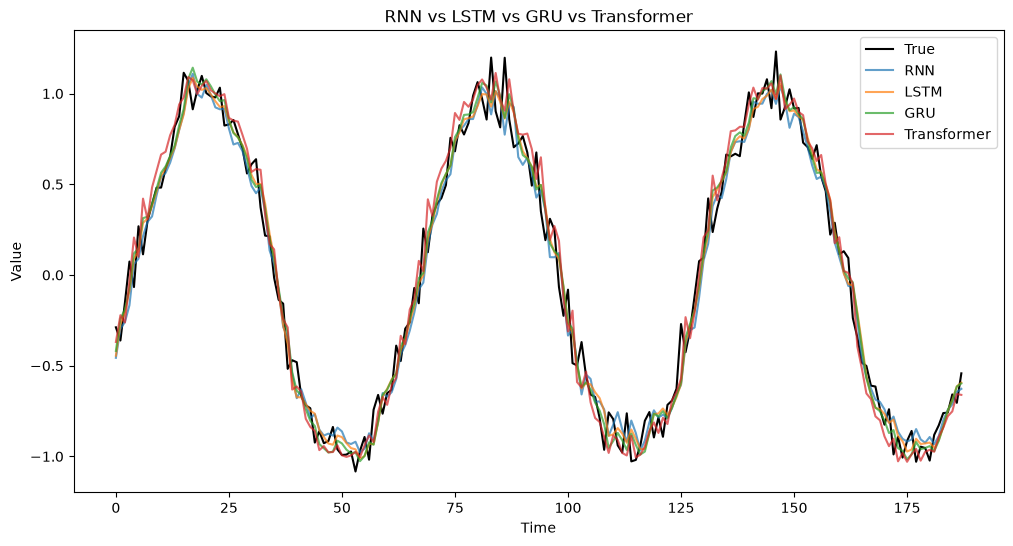

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math

# =========================
# 1️⃣ 產生時間序列資料
# =========================
np.random.seed(0)
torch.manual_seed(0)

t = np.linspace(0, 100, 1000)
data = np.sin(t) + 0.1*np.random.randn(len(t))

seq_length = 60

X, Y = [], []
for i in range(len(data) - seq_length):
    X.append(data[i:i+seq_length])
    Y.append(data[i+seq_length])

X = np.array(X)
Y = np.array(Y)

train_size = int(len(X) * 0.8)

X_train = torch.tensor(X[:train_size], dtype=torch.float32).unsqueeze(-1)
Y_train = torch.tensor(Y[:train_size], dtype=torch.float32).unsqueeze(-1)

X_test = torch.tensor(X[train_size:], dtype=torch.float32).unsqueeze(-1)
Y_test = torch.tensor(Y[train_size:], dtype=torch.float32).unsqueeze(-1)


# =========================
# 2️⃣ 定義模型
# =========================

class RNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(1, 50, batch_first=True)
        self.fc = nn.Linear(50, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 50, batch_first=True)
        self.fc = nn.Linear(50, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


class GRUModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(1, 50, batch_first=True)
        self.fc = nn.Linear(50, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :])


# 🔷 Positional Encoding
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() *
            (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


# 🔷 強化版 Transformer
class TransformerModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.d_model = 64

        self.embedding = nn.Linear(1, self.d_model)
        self.pos_encoder = PositionalEncoding(self.d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=self.d_model,
            nhead=8,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=4
        )

        self.fc = nn.Linear(self.d_model, 1)

    def forward(self, x):
        x = self.embedding(x)
        x = self.pos_encoder(x)
        x = self.transformer(x)
        return self.fc(x[:, -1, :])


# =========================
# 3️⃣ Warmup Scheduler
# =========================

class WarmupScheduler:
    def __init__(self, optimizer, d_model, warmup_steps=200):
        self.optimizer = optimizer
        self.d_model = d_model
        self.warmup_steps = warmup_steps
        self.step_num = 0

    def step(self):
        self.step_num += 1
        lr = (self.d_model ** -0.5) * min(
            self.step_num ** -0.5,
            self.step_num * (self.warmup_steps ** -1.5)
        )
        for p in self.optimizer.param_groups:
            p['lr'] = lr


# =========================
# 4️⃣ 訓練函數
# =========================

def train_basic(model, epochs=50):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for _ in range(epochs):
        model.train()
        output = model(X_train)
        loss = criterion(output, Y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    return model


def train_transformer(model, epochs=50):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    scheduler = WarmupScheduler(optimizer, model.d_model)

    for _ in range(epochs):
        model.train()
        output = model(X_train)
        loss = criterion(output, Y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()

    return model


def evaluate(model):
    model.eval()
    with torch.no_grad():
        pred = model(X_test)
        mse = nn.MSELoss()(pred, Y_test).item()
    return pred.numpy(), mse


# =========================
# 5️⃣ 訓練四種模型
# =========================

rnn_model = train_basic(RNNModel())
lstm_model = train_basic(LSTMModel())
gru_model = train_basic(GRUModel())
transformer_model = train_transformer(TransformerModel())

# =========================
# 6️⃣ 評估
# =========================

rnn_pred, rnn_mse = evaluate(rnn_model)
lstm_pred, lstm_mse = evaluate(lstm_model)
gru_pred, gru_mse = evaluate(gru_model)
trans_pred, trans_mse = evaluate(transformer_model)

print("RNN         MSE:", rnn_mse)
print("LSTM        MSE:", lstm_mse)
print("GRU         MSE:", gru_mse)
print("Transformer MSE:", trans_mse)

# =========================
# 7️⃣ 畫圖比較
# =========================

plt.figure(figsize=(12,6))

plt.plot(Y_test.numpy(), label="True", color="black")
plt.plot(rnn_pred, label="RNN", alpha=0.7)
plt.plot(lstm_pred, label="LSTM", alpha=0.7)
plt.plot(gru_pred, label="GRU", alpha=0.7)
plt.plot(trans_pred, label="Transformer", alpha=0.7)

plt.legend()
plt.title("RNN vs LSTM vs GRU vs Transformer")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

In [28]:
data.shape

(1000,)

In [26]:
trans_pred.shape

(188, 1)

In [3]:
X_train.shape

torch.Size([752, 60, 1])

In [4]:
X.shape

(940, 60)

In [37]:
X[0,:]

array([ 0.17640523,  0.13994874,  0.29673933,  0.5198964 ,  0.5765429 ,
        0.38213692,  0.66014691,  0.62961773,  0.7075919 ,  0.82494645,
        0.85641576,  1.03713363,  1.00857745,  0.97607297,  1.03007328,
        1.03096751,  1.14893346,  0.97092829,  1.00474345,  0.86027394,
        0.6531635 ,  0.92750808,  0.89364207,  0.66995277,  0.90066518,
        0.45102884,  0.51784534,  0.4062165 ,  0.4856239 ,  0.3833656 ,
        0.15364117,  0.0762963 , -0.15035015, -0.35908642, -0.29362123,
       -0.33842705, -0.32272006, -0.41273563, -0.65359482, -0.72082516,
       -0.86426891, -0.96263114, -1.04425624, -0.72280507, -1.00391168,
       -1.02227716, -1.11947642, -0.92222144, -1.15712248, -1.0028    ,
       -1.0470392 , -0.88518276, -0.93208449, -0.94737784, -0.77214067,
       -0.65879488, -0.6202575 , -0.51566679, -0.52288543, -0.40466669])

In [39]:
Y[1]

np.float64(-0.21211052040789957)

In [23]:
X_train

tensor([[[ 0.1764],
         [ 0.1399],
         [ 0.2967],
         ...,
         [-0.5157],
         [-0.5229],
         [-0.4047]],

        [[ 0.1399],
         [ 0.2967],
         [ 0.5199],
         ...,
         [-0.5229],
         [-0.4047],
         [-0.3409]],

        [[ 0.2967],
         [ 0.5199],
         [ 0.5765],
         ...,
         [-0.4047],
         [-0.3409],
         [-0.2121]],

        ...,

        [[-0.3804],
         [-0.2403],
         [-0.3874],
         ...,
         [-0.7921],
         [-0.7863],
         [-0.8865]],

        [[-0.2403],
         [-0.3874],
         [-0.0778],
         ...,
         [-0.7863],
         [-0.8865],
         [-0.6558]],

        [[-0.3874],
         [-0.0778],
         [ 0.1468],
         ...,
         [-0.8865],
         [-0.6558],
         [-0.6182]]])

C:\Users\jeffe\AppData\Local\Temp\ipykernel_33376\314768199.py:148: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


RNN         MSE: 0.015633955597877502
LSTM        MSE: 0.013154404237866402
GRU         MSE: 0.01343325711786747
Transformer MSE: 0.010611085221171379


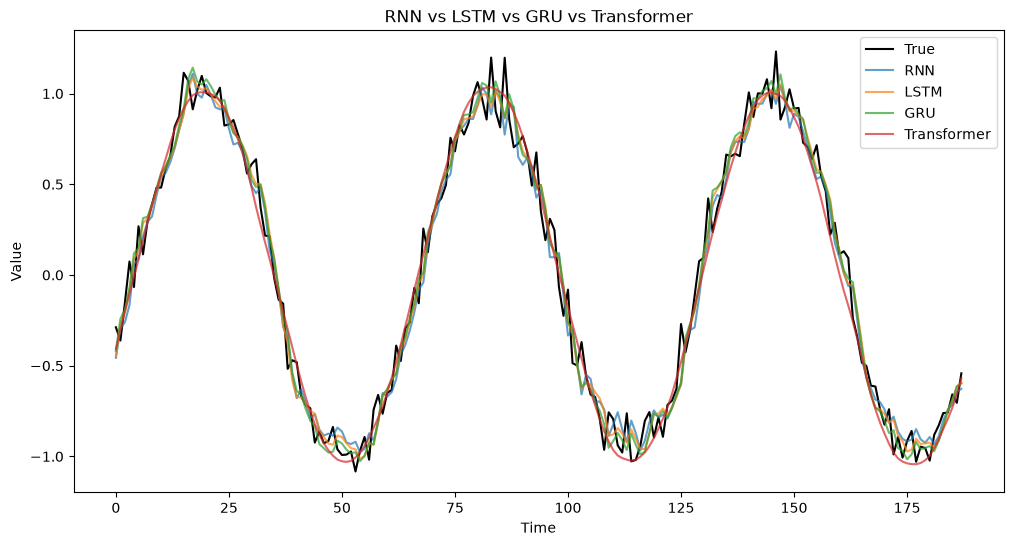

In [40]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math

# =========================
# 1️⃣ 產生時間序列資料
# =========================
np.random.seed(0)
torch.manual_seed(0)

t = np.linspace(0, 100, 1000)
data = np.sin(t) + 0.1*np.random.randn(len(t))

seq_length = 60

X, Y = [], []
for i in range(len(data) - seq_length):
    X.append(data[i:i+seq_length])
    Y.append(data[i+seq_length])

X = np.array(X)
Y = np.array(Y)

train_size = int(len(X) * 0.8)

X_train = torch.tensor(X[:train_size], dtype=torch.float32).unsqueeze(-1)
Y_train = torch.tensor(Y[:train_size], dtype=torch.float32).unsqueeze(-1)

X_test = torch.tensor(X[train_size:], dtype=torch.float32).unsqueeze(-1)
Y_test = torch.tensor(Y[train_size:], dtype=torch.float32).unsqueeze(-1)


# =========================
# 2️⃣ 定義模型
# =========================

class RNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(1, 50, batch_first=True)
        self.fc = nn.Linear(50, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 50, batch_first=True)
        self.fc = nn.Linear(50, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


class GRUModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(1, 50, batch_first=True)
        self.fc = nn.Linear(50, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :])


# 🔷 Positional Encoding
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() *
            (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


# # 🔷 強化版 Transformer
# class TransformerModel(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.d_model = 64

#         self.embedding = nn.Linear(1, self.d_model)
#         self.pos_encoder = PositionalEncoding(self.d_model)

#         encoder_layer = nn.TransformerEncoderLayer(
#             d_model=self.d_model,
#             nhead=8,
#             dim_feedforward=128,
#             dropout=0.1,
#             batch_first=True
#         )

#         self.transformer = nn.TransformerEncoder(
#             encoder_layer,
#             num_layers=4
#         )

#         self.fc = nn.Linear(self.d_model, 1)

#     def forward(self, x):
#         x = self.embedding(x)
#         x = self.pos_encoder(x)
#         x = self.transformer(x)
#         return self.fc(x[:, -1, :])


class TransformerModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.d_model = 32

        # input feature: 1 → embedding dimension
        self.embedding = nn.Linear(1, self.d_model)

        self.pos_encoder = PositionalEncoding(
            self.d_model,
            max_len=500
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=self.d_model,
            nhead=4,
            dim_feedforward=64,
            dropout=0.05,
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.norm = nn.LayerNorm(self.d_model)

        self.fc = nn.Sequential(
            nn.Linear(self.d_model, 16),
            nn.ReLU(),
            nn.Linear(16,1)
        )


    def forward(self,x):

        # (batch, seq, 1)
        x = self.embedding(x)

        # 加入位置資訊
        x = self.pos_encoder(x)

        # Transformer Encoder
        x = self.transformer(x)

        # LayerNorm
        x = self.norm(x)


        # 使用全部 timestep
        # (batch, seq, dim)
        x = x.mean(dim=1)


        return self.fc(x)

# =========================
# 3️⃣ Warmup Scheduler
# =========================

class WarmupScheduler:
    def __init__(self, optimizer, d_model, warmup_steps=200):
        self.optimizer = optimizer
        self.d_model = d_model
        self.warmup_steps = warmup_steps
        self.step_num = 0

    def step(self):
        self.step_num += 1
        lr = (self.d_model ** -0.5) * min(
            self.step_num ** -0.5,
            self.step_num * (self.warmup_steps ** -1.5)
        )
        for p in self.optimizer.param_groups:
            p['lr'] = lr


# =========================
# 4️⃣ 訓練函數
# =========================

def train_basic(model, epochs=50):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for _ in range(epochs):
        model.train()
        output = model(X_train)
        loss = criterion(output, Y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    return model


# def train_transformer(model, epochs=50):
#     criterion = nn.MSELoss()
#     optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
#     scheduler = WarmupScheduler(optimizer, model.d_model)

#     for _ in range(epochs):
#         model.train()
#         output = model(X_train)
#         loss = criterion(output, Y_train)

#         optimizer.zero_grad()
#         loss.backward()
#         optimizer.step()
#         scheduler.step()

#     return model
def train_transformer(model, epochs=300):

    criterion = nn.MSELoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-5
    )


    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )


    for epoch in range(epochs):

        model.train()

        output = model(X_train)

        loss = criterion(
            output,
            Y_train
        )


        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()

        scheduler.step()


    return model

def evaluate(model):
    model.eval()
    with torch.no_grad():
        pred = model(X_test)
        mse = nn.MSELoss()(pred, Y_test).item()
    return pred.numpy(), mse


# =========================
# 5️⃣ 訓練四種模型
# =========================

rnn_model = train_basic(RNNModel())
lstm_model = train_basic(LSTMModel())
gru_model = train_basic(GRUModel())
transformer_model = train_transformer(TransformerModel())

# =========================
# 6️⃣ 評估
# =========================

rnn_pred, rnn_mse = evaluate(rnn_model)
lstm_pred, lstm_mse = evaluate(lstm_model)
gru_pred, gru_mse = evaluate(gru_model)
# trans_pred, trans_mse = evaluate(transformer_model)

print("RNN         MSE:", rnn_mse)
print("LSTM        MSE:", lstm_mse)
print("GRU         MSE:", gru_mse)
print("Transformer MSE:", trans_mse)

# =========================
# 7️⃣ 畫圖比較
# =========================

plt.figure(figsize=(12,6))

plt.plot(Y_test.numpy(), label="True", color="black")
plt.plot(rnn_pred, label="RNN", alpha=0.7)
plt.plot(lstm_pred, label="LSTM", alpha=0.7)
plt.plot(gru_pred, label="GRU", alpha=0.7)
plt.plot(trans_pred, label="Transformer", alpha=0.7)

plt.legend()
plt.title("RNN vs LSTM vs GRU vs Transformer")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

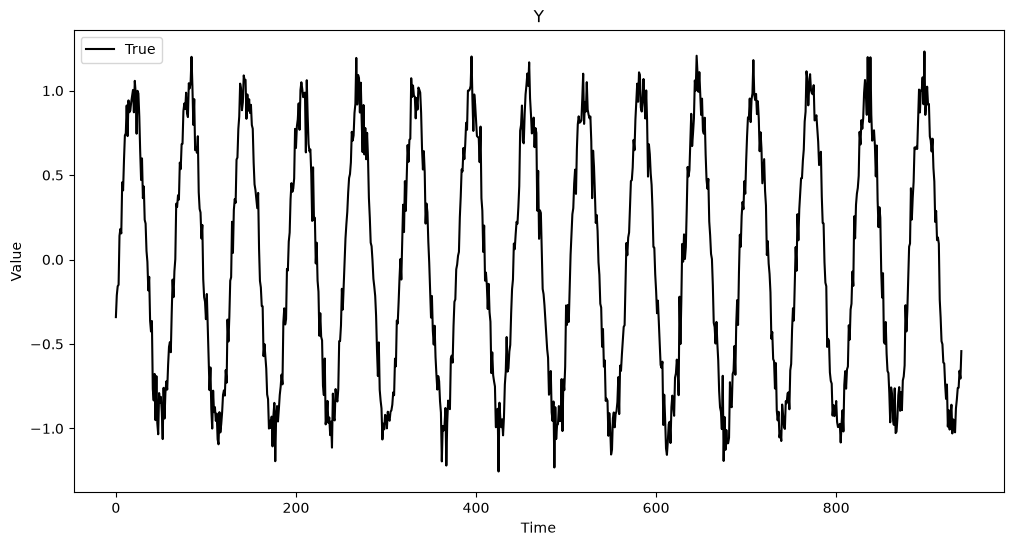

In [43]:
plt.figure(figsize=(12,6))

plt.plot(Y, label="True", color="black")
# plt.plot(rnn_pred, label="RNN", alpha=0.7)
# plt.plot(lstm_pred, label="LSTM", alpha=0.7)
# plt.plot(gru_pred, label="GRU", alpha=0.7)
# plt.plot(trans_pred, label="Transformer", alpha=0.7)

plt.legend()
plt.title("Y")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()